In [13]:
import pandas as pd, scipy.stats as stats, matplotlib.pyplot as plt, seaborn as sns
from statsmodels.stats.multicomp import pairwise_tukeyhsd


url = "https://raw.githubusercontent.com/dataprofessor/data/refs/heads/master/penguins_cleaned.csv"

df = pd.read_csv(url)
df.head(1)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181,3750,male


Text(0.5, 0.98, 'Fig. 1: Bar chart')

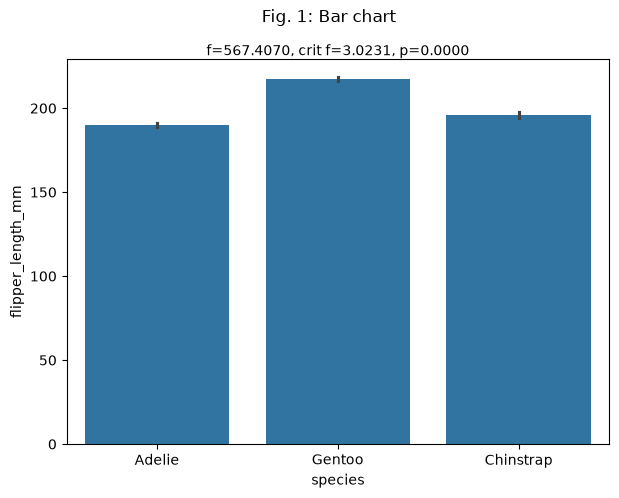

In [14]:
plt.figure(figsize=(7,5))
#[...], [...], [...]
species = df['species'].unique()
species_vars = [
    df.loc[df['species'] == s, "flipper_length_mm"] for s in species
    ]
f, p = stats.f_oneway(*species_vars)
alpha = 0.05
dfb = len(species) - 1
dfw = len(df['species']) - len(species) #df['species'].count()
crit_f = stats.f.ppf(1- alpha, dfb,dfw)
bar = sns.barplot(data=df, x='species', y='flipper_length_mm')
text=f'f={f:.4f}, crit f={crit_f:.4f}, p={p:.4f}'
bar.text(x=0.5, y= 1.01, s=text, ha='center', transform=bar.transAxes)
plt.suptitle("Fig. 1: Bar chart")

In [18]:
tukey = pairwise_tukeyhsd(
    endog=df['flipper_length_mm'],
    groups=df['species'],
    alpha= alpha, 
)

print(tukey)

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
   Adelie Chinstrap   5.7208   0.0  3.4144  8.0272   True
   Adelie    Gentoo  27.1326   0.0 25.1924 29.0727   True
Chinstrap    Gentoo  21.4118   0.0 19.0236 23.7999   True
---------------------------------------------------------


<Axes: xlabel='species', ylabel='flipper_length_mm'>

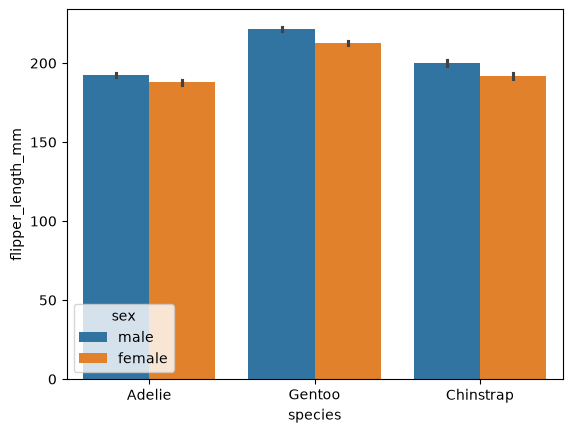

In [20]:
sns.barplot(data=df, x='species', y='flipper_length_mm', hue='sex')

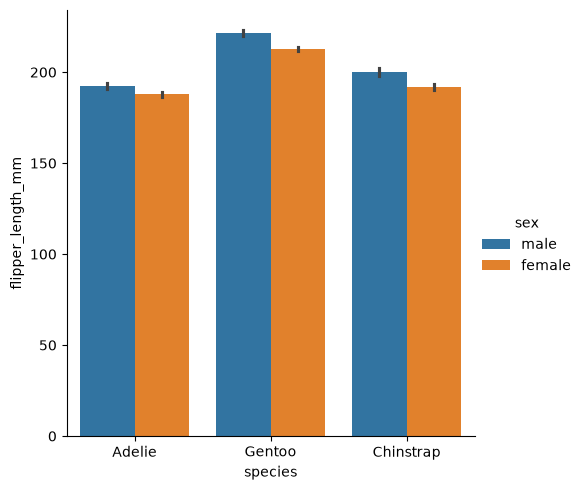

In [21]:
sns.catplot(data= df, x= 'species', y= 'flipper_length_mm', hue= 'sex', kind= "bar")

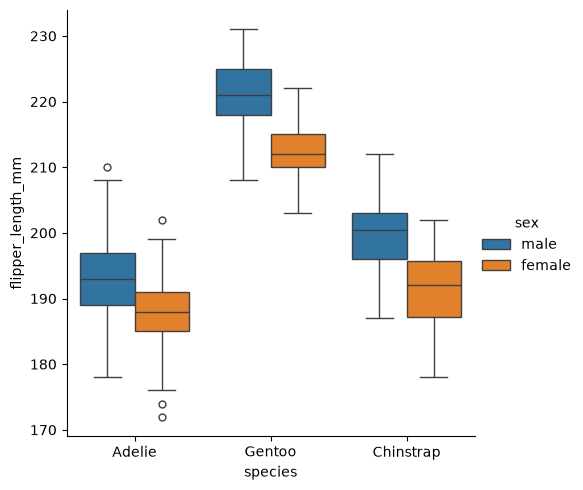

In [23]:
sns.catplot(data= df, x= 'species', y= 'flipper_length_mm', hue= 'sex', kind= "box")

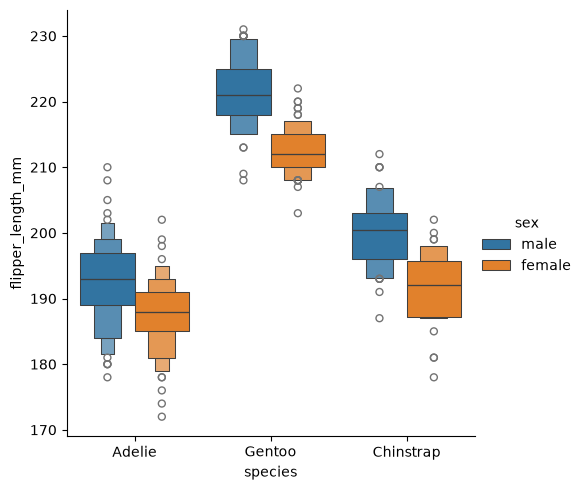

In [24]:
sns.catplot(data= df, x= 'species', y= 'flipper_length_mm', hue= 'sex', kind= "boxen")

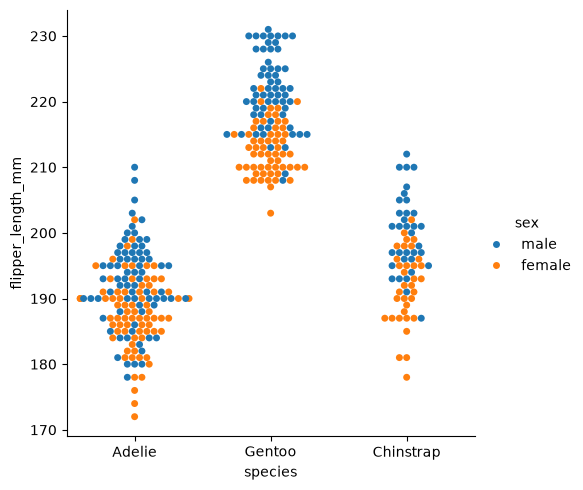

In [26]:
sns.catplot(data= df, x= 'species', y= 'flipper_length_mm', hue= 'sex', kind= "swarm")

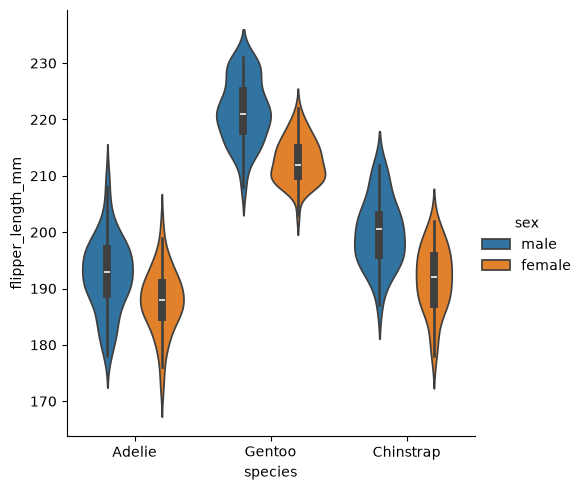

In [27]:
sns.catplot(data= df, x= 'species', y= 'flipper_length_mm', hue= 'sex', kind= "violin")

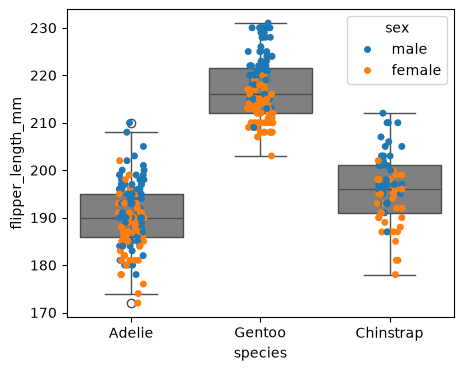

In [30]:
plt.figure(figsize=(5,4))
box = sns.boxplot(data= df, x= 'species', y= 'flipper_length_mm', color= 'gray')
strip = sns.stripplot(data= df, x= 'species', y= 'flipper_length_mm', hue= 'sex')
plt.show()